# DistilBERT — Minh họa thực nghiệm của Quân, Nhóm 5
Dựa trên repository Doris1808/covid19-fake-news-nhom5, kiểm tra ngày 29/10/2026.
Nhánh `quan/distilbert-results` chứa cùng code DistilBERT với main tại thời điểm kiểm tra và có thêm báo cáo ba seed.

**Chuẩn bị:** bật Internet, chọn GPU; gắn Dataset chứa model đã fine-tune.
Notebook không chứa trọng số và chưa có output chạy GPU mới. Chạy lần lượt ô 1–12 để demo.
Đổi SEED ở ô 1 theo model bạn gắn. Chọn 123 nếu có model seed123 (F1 Validation cao nhất trong báo cáo).
Các ô 13–15 dùng để kiểm tra train hoặc tái huấn luyện; mặc định tắt.

> **BẢN KAGGLE CŨ — ĐÃ BỔ SUNG GIẢI THÍCH THEO LAB07 (09/11/2026).** Đây là notebook `distilbert-v2-fix (2).ipynb` được chèn thêm ô để trình bày rõ pipeline, **không phải một thí nghiệm mới**. Các output đã có thuộc lần demo checkpoint **seed 42**; mọi ô thêm mới đều **chưa chạy**, không giả lập số liệu. Chưa bật `RUN_SMOKE`, `RUN_FULL_TRAIN`, `EVALUATE_NEW_RUN` nếu chỉ muốn trình bày kết quả cũ.

**Cách import Kaggle:** Upload `.ipynb` → gắn lại dữ liệu đầu vào (`Add Input`, gồm mã nguồn và model seed 42) → bật Internet/GPU nếu cần → chạy lần lượt các ô. Không chọn `Run All` nếu chưa kiểm tra đường dẫn và dữ liệu. Để giữ bằng chứng gốc, hãy lưu phiên bản notebook trước khi chạy lại.


## Ô 1 — Mã nguồn và đường dẫn
Ưu tiên clone nhánh kết quả. Nếu clone lỗi mạng, upload ZIP mã nguồn thành Kaggle Dataset,
Add Input rồi chạy lại ô này. ZIP cần có `src`, `configs`, `data/raw`, `reports/distilbert`.
Chỉ dùng một GPU để effective batch size của lượt train là 8 × 4 = 32.


In [1]:
import os, sys, json, subprocess, shutil, zipfile, re
from pathlib import Path
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
SEED = 42  
MODEL_DIR_OVERRIDE = None  # Chỉ nhập đường dẫn khi cần, mặc định dùng model seed42 hiện có
PROJECT = Path('/kaggle/working/nhom5-distilbert-demo')
REPO_URL = 'https://github.com/Doris1808/covid19-fake-news-nhom5.git'
INPUT = Path('/kaggle/input')
def valid_source(p):
    return (p/'src/finetune.py').is_file() and (p/'data/raw/test.csv').is_file()
if not valid_source(PROJECT):
    folders = [p.parent.parent for p in INPUT.rglob('configs/distilbert.json')]
    source = next((p for p in folders if valid_source(p)), None)
    if source:
        shutil.copytree(source, PROJECT, dirs_exist_ok=True)
    else:
        for archive in INPUT.rglob('*.zip'):
            with zipfile.ZipFile(archive) as z:
                names = z.namelist()
                if not any(n.endswith('src/finetune.py') for n in names):
                    continue
                target = Path('/kaggle/working/source_unpacked')
                target.mkdir(exist_ok=True)
                for info in z.infolist():
                    dest = (target/info.filename).resolve()
                    if not dest.is_relative_to(target.resolve()):
                        raise ValueError('ZIP có đường dẫn không hợp lệ')
                z.extractall(target)
                source = next((p.parent.parent for p in target.rglob('configs/distilbert.json')
                               if valid_source(p.parent.parent)), None)
                if source:
                    shutil.copytree(source, PROJECT, dirs_exist_ok=True)
                    break
        if not valid_source(PROJECT):
            if PROJECT.exists():
                raise RuntimeError('Thư mục mã nguồn chưa đủ. Gắn Dataset ZIP mã nguồn rồi chạy lại.')
            subprocess.run(['git','clone','--depth','1','--branch','quan/distilbert-results',
                            REPO_URL,str(PROJECT)], check=True)
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
REPORTS = PROJECT/'reports/distilbert'
assert (REPORTS/'seed123/test_metrics.json').exists(), 'Thiếu reports: hãy dùng nhánh quan/distilbert-results.'
OUT = Path('/kaggle/working')/f'demo_distilbert_seed{SEED}'
OUT.mkdir(exist_ok=True)
cfg = json.loads((PROJECT/'configs/distilbert.json').read_text())
print('Mã nguồn:', PROJECT)
print('Seed demo:', SEED)
print('Kết quả demo sẽ lưu:', OUT)


Mã nguồn: /kaggle/working/nhom5-distilbert-demo
Seed demo: 42
Kết quả demo sẽ lưu: /kaggle/working/demo_distilbert_seed42


## Ô 2 — Cài đúng thư viện của repository
Nếu Kaggle yêu cầu restart session, restart rồi chạy lại ô 1 và tiếp tục ô 3.
Khi thiếu Internet, cần chuẩn bị thư viện trước; ZIP mã nguồn không thay thế các gói pip.


In [2]:
subprocess.run([sys.executable,'-m','pip','install','-r',str(PROJECT/'requirements.txt')], check=True)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 51.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 120.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 16.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 101.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 45.3 MB/s  0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.29.0
    Uninstalling huggingface_hub-1.29.0:
      Successfully uninstalled huggingface_hub-1.29.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.1
    Uninstalling tokenizers-0.23.1:
      Successfully uninstalled tokenizers-0.23.1
  Attempting uninstall: transformers
    Found existing installation: transformers 5.16.1
    Uninstalling transformers-5.16.1:
      Successfully uninstalled transformers-5.16.1



ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-r', '/kaggle/working/nhom5-distilbert-demo/requirements.txt'], returncode=0)

## Ô 3 — Kiểm tra GPU, phiên bản và cấu hình


In [3]:
import torch, transformers, pandas as pd, numpy as np
from IPython.display import display
from src.common import load_split, scores, fingerprint, save_json
from src.predict import load_model
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__, '| Transformers:', transformers.__version__)
print('CUDA:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('Bật Accelerator GPU rồi khởi động lại phiên trước khi chạy tiếp.')
device = torch.device('cuda:0')
print('GPU:', torch.cuda.get_device_name(0), '| GPU nhìn thấy:', torch.cuda.device_count())
display(pd.DataFrame([cfg]))
save_json({'python':sys.version.split()[0], 'torch':torch.__version__,
           'transformers':transformers.__version__, 'gpu':torch.cuda.get_device_name(0)}, OUT/'demo_environment.json')


Python: 3.13.15
PyTorch: 2.11.0+cu128 | Transformers: 4.57.1
CUDA: True
GPU: Tesla T4 | GPU nhìn thấy: 1


,model_name,seeds,epochs,learning_rate,max_length,train_batch_size,eval_batch_size,gradient_accumulation_steps,weight_decay,warmup_ratio
0,distilbert/distilbert-base-uncased,"[42, 123, 2024]",4,0.00002,128,8,16,4,0.01,0.1


### Cách trình bày Ô 1–3 với cô

1. **Ô 1:** Lấy mã nguồn `src/finetune.py`, `configs/distilbert.json`, `data/raw/*.csv` và báo cáo từ repository Nhóm 5 (không có quá trình train ở bước này).
2. **Ô 2:** Cài thư viện để đọc dữ liệu, nạp trọng số pretrained/checkpoint và chạy suy luận.
3. **Ô 3:** Kiểm tra GPU và siêu tham số thực tế (`epochs=4`, `learning_rate=2e-5`, `max_length=128`, batch train 8, tích lũy gradient 4). Các giá trị hiện ra được lấy từ **file cấu hình**.

**Nói với cô:** “Em chạy trên Kaggle GPU. Em giữ cùng cấu hình khi thử ba seed để đánh giá tính ổn định. Notebook demo này đang nạp một checkpoint đã fine-tune; nó chưa train lại mô hình.”

## Ô 4 — Dữ liệu đi vào mô hình
Giữ nguyên Train/Validation/Test. Train cập nhật trọng số; Validation chọn checkpoint;
Test đo kết quả sau khi chốt cấu hình. Hàm load_split kiểm tra cột, nhãn, văn bản rỗng;
không xóa stopword, không stemming, không biến văn bản thành TF-IDF cho DistilBERT.


In [4]:
frames = {s:load_split(s, PROJECT/'data/raw') for s in ['train','val','test']}
stats = pd.DataFrame([{'split':s,'samples':len(df), **df.label.value_counts().to_dict()}
                      for s,df in frames.items()])
display(stats)
display(frames['train'].groupby('label',group_keys=False).head(2))
reference_cfg = json.loads((REPORTS/f'seed{SEED}/run_config.json').read_text())
reference_test = json.loads((REPORTS/f'seed{SEED}/test_metrics.json').read_text())
hashes = {s:fingerprint(PROJECT/f'data/raw/{s}.csv') for s in frames}
expected = dict(reference_cfg['dataset_sha256'], test=reference_test['dataset_sha256'])
display(pd.DataFrame([{'split':s,'SHA256 trùng báo cáo':hashes[s]==expected[s]} for s in frames]))
assert hashes == expected, 'Dữ liệu khác báo cáo; chưa thể đối chiếu trực tiếp các metric.'
stats.to_csv(OUT/'dataset_stats.csv',index=False)


,split,samples,real,fake
0,train,6420,3360,3060
1,val,2140,1120,1020
2,test,2140,1120,1020


,id,tweet,label
0,1,The CDC currently reports 99031 deaths. In gen...,real
1,2,States reported 1121 deaths a small rise from ...,real
2,3,Politically Correct Woman (Almost) Uses Pandem...,fake
7,8,Obama Calls Trump’s Coronavirus Response A Cha...,fake


,split,SHA256 trùng báo cáo
0,train,True
1,val,True
2,test,True


### Bổ sung theo Lab07 — Quan sát dataset (không làm thay đổi dữ liệu)

Bộ dữ liệu CONSTRAINT@AAAI2021 gồm **10.700 mẫu**, các tệp đã chia sẵn: **Train 6.420 / Validation 2.140 / Test 2.140**. Văn bản nằm trong cột `tweet`, nhãn ở `label` (giá trị chữ `fake` hoặc `real`). Ô 4 bên trên đã đối chiếu SHA256 với báo cáo của lần train gốc. **SHA256 trùng không chứng minh các tập không có văn bản trùng nhau**, nên cần kiểm toán tiếp.

**Nói với cô:** “Em dùng đúng ba split có sẵn, không chia lại ngẫu nhiên. Train để cập nhật trọng số, Validation để chọn checkpoint, Test chỉ dùng để đánh giá sau khi đã chốt cấu hình.”

Số lượng từng lớp trong từng split:


label,fake,real
train,3060,3360
val,1020,1120
test,1020,1120


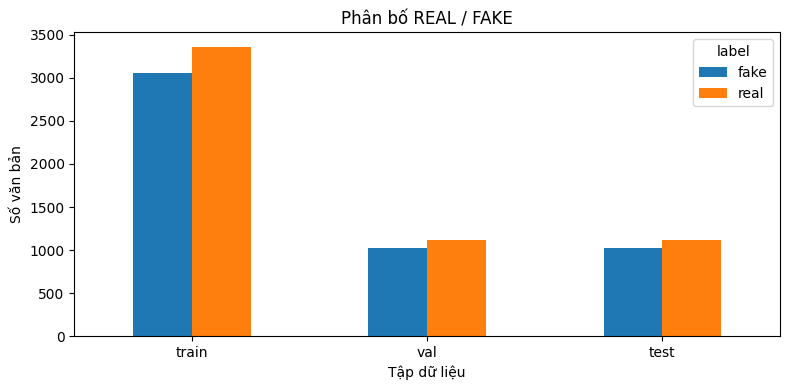

Ví dụ văn bản và nhãn (từ tập Train):


,tweet,label
0,The CDC currently reports 99031 deaths. In gen...,real
1,States reported 1121 deaths a small rise from ...,real
2,Politically Correct Woman (Almost) Uses Pandem...,fake
3,#IndiaFightsCorona: We have 1524 #COVID testin...,real


In [5]:
import matplotlib.pyplot as plt

label_counts = pd.DataFrame({
    split: df['label'].value_counts().reindex(['fake', 'real'], fill_value=0)
    for split, df in frames.items()
}).T
print('Số lượng từng lớp trong từng split:')
display(label_counts)
ax = label_counts.plot(kind='bar', figsize=(8, 4), rot=0)
ax.set(xlabel='Tập dữ liệu', ylabel='Số văn bản', title='Phân bố REAL / FAKE')
plt.tight_layout()
plt.show()

print('Ví dụ văn bản và nhãn (từ tập Train):')
display(frames['train'][['tweet','label']].head(4))


### Kiểm tra dữ liệu trùng lặp trước khi kết luận về kết quả

Phép kiểm tra chuẩn hóa **chữ thường, khoảng trắng** rồi so sánh văn bản. Nó chỉ phát hiện những trường hợp trùng nhau theo quy tắc này; **không phải kiểm tra ngữ nghĩa tương đương**. In số mẫu trùng trong từng split, số nội dung trùng giữa các split và nhãn mâu thuẫn. **Không tự động xóa hoặc sửa dữ liệu đã dùng cho thí nghiệm cũ.** Nếu có overlap Train–Test, cần ghi nhận nguy cơ rò rỉ và cân nhắc thử nghiệm riêng trên tập đã loại trùng.

In [6]:
import re
from itertools import combinations

def normalize_for_audit(text):
    return re.sub(r'\s+', ' ', str(text).strip().casefold())

audit_frames = {
    split: df.assign(_audit_text=df['tweet'].fillna('').map(normalize_for_audit))
    for split, df in frames.items()
}

audit_rows = []
for split, df in audit_frames.items():
    dup_rows = int(df['_audit_text'].duplicated().sum())
    conflicts = int((df.groupby('_audit_text')['label'].nunique() > 1).sum())
    audit_rows.append({'split':split, 'samples':len(df),
                       'duplicate_text_rows':dup_rows,
                       'conflicting_label_text_groups':conflicts})
print('Kiểm tra trùng trong từng tập:')
display(pd.DataFrame(audit_rows))

overlap_rows = []
for left, right in combinations(('train','val','test'), 2):
    l = audit_frames[left][['_audit_text','label','tweet']].drop_duplicates('_audit_text')
    r = audit_frames[right][['_audit_text','label','tweet']].drop_duplicates('_audit_text')
    pairs = l.merge(r, on='_audit_text', suffixes=(f'_{left}',f'_{right}'))
    conflict = pairs[f'label_{left}'] != pairs[f'label_{right}']
    overlap_rows.append({'pair':f'{left} / {right}',
                         'overlapping_distinct_texts':len(pairs),
                         'conflicting_labels_in_matching_pairs':int(conflict.sum())})
    if len(pairs):
        print(f'Ví dụ trùng {left} / {right}:')
        display(pairs[[f'tweet_{left}', f'label_{left}', f'label_{right}']].head(3))
print('Trùng giữa các tập:')
display(pd.DataFrame(overlap_rows))
pd.DataFrame(audit_rows).to_csv(OUT/'audit_within_splits.csv', index=False)
pd.DataFrame(overlap_rows).to_csv(OUT/'audit_overlap_between_splits.csv', index=False)
print('Đã lưu bảng audit trong OUT; CSV dữ liệu gốc không bị thay đổi.')


Kiểm tra trùng trong từng tập:


,split,samples,duplicate_text_rows,conflicting_label_text_groups
0,train,6420,0,0
1,val,2140,0,0
2,test,2140,0,0


Ví dụ trùng train / val:


,tweet_train,label_train,label_val
0,Our combined total of confirmed and probable c...,real,real


Ví dụ trùng train / test:


,tweet_train,label_train,label_test
0,Audio from WhatsApp in which the head of cardi...,fake,fake
1,Video shows muslim women spitting in plastic b...,fake,fake


Trùng giữa các tập:


,pair,overlapping_distinct_texts,conflicting_labels_in_matching_pairs
0,train / val,1,0
1,train / test,2,0
2,val / test,0,0


Đã lưu bảng audit trong OUT; CSV dữ liệu gốc không bị thay đổi.


**Cách đọc kết quả audit:** Nếu không có trùng nội bộ hoặc giữa các split theo quy tắc này, đó là tín hiệu tốt nhưng chưa chứng minh dữ liệu hoàn toàn không rò rỉ. Nếu có trùng, không được nói F1 cao là do overfitting chỉ dựa trên overlap; cần phân tích riêng sự ảnh hưởng và làm thí nghiệm đối chứng.

## Ô 5 — Tìm model đã train trong Kaggle Input
File JSON metric không phải trọng số. Cần thư mục `model` có `config.json`,
`model.safetensors` (hoặc pytorch_model.bin) và tokenizer.
Nếu Input còn giữ ZIP outputs, ô này chỉ giải nén model và JSON của seed đang demo.


In [7]:
from pathlib import Path
import json
from src.predict import load_model

SEED = 42

MODEL_DIR = Path(
    "/kaggle/input/datasets/boqunlnghong/"
    "nhom5-distilbert-seed42-demo-2910/"
    "outputs/distilbert/seed_42/model"
)

RUN_DIR = MODEL_DIR.parent

if not (MODEL_DIR / "config.json").exists():
    raise FileNotFoundError(f"Không tìm thấy model: {MODEL_DIR}")

run_config_path = RUN_DIR / "run_config.json"

if not run_config_path.exists():
    raise FileNotFoundError(f"Thiếu file: {run_config_path}")

loaded_cfg = json.loads(run_config_path.read_text())

assert loaded_cfg["seed"] == SEED, "Model không thuộc seed42."
assert not loaded_cfg.get("smoke", False), "Đây là model chạy thử."

for key in cfg:
    assert loaded_cfg[key] == cfg[key], f"Khác cấu hình: {key}"

reference_cfg = json.loads(
    (REPORTS / "seed42" / "run_config.json").read_text()
)

assert (
    loaded_cfg["dataset_sha256"]
    == reference_cfg["dataset_sha256"]
), "Dữ liệu của model khác báo cáo."

print("Đang nạp model:", MODEL_DIR)

tokenizer, model = load_model(MODEL_DIR)
model = model.to(device).eval()
MAX_LENGTH = loaded_cfg["max_length"]

print("Nạp model thành công.")
print("Seed:", SEED)
print("Thiết bị:", next(model.parameters()).device)
print("Max length:", MAX_LENGTH)
print("Ánh xạ nhãn:", model.config.id2label)

Đang nạp model: /kaggle/input/datasets/boqunlnghong/nhom5-distilbert-seed42-demo-2910/outputs/distilbert/seed_42/model
Nạp model thành công.
Seed: 42
Thiết bị: cuda:0
Max length: 128
Ánh xạ nhãn: {0: 'fake', 1: 'real'}


### Phân biệt hai hành động: nạp model và fine-tuning

Ô 5 đang **nạp checkpoint seed 42 đã lưu**, không nạp DistilBERT trắng để train lại. Cần có thư mục model với `config.json` và trọng số, kèm `run_config.json`. File `metrics.json` **không chứa trọng số**. Khi import sang Kaggle session mới, phải **Add Input** dataset model `nhom5-distilbert-seed42-demo-2910`; nếu đường dẫn khác, sửa `MODEL_DIR` ở Ô 5 cho khớp Kaggle Input. Việc nạp một checkpoint cố định không thể chuyển sang seed 123 chỉ bằng thay biến `SEED`.

## Ô 6 — Token hóa một câu
Tokenizer uncased chuyển văn bản thành các token/subword và ID, thêm [CLS]/[SEP].
Câu dài bị cắt ở 128 token; khi gom batch, DataCollatorWithPadding của code train
đệm đến câu dài nhất trong batch. attention_mask phân biệt token thật với phần đệm.


In [8]:
TEXT = frames['train'].iloc[0].tweet
encoded = tokenizer(TEXT, return_tensors='pt', truncation=True, max_length=MAX_LENGTH)
print('Văn bản:', TEXT)
display(pd.DataFrame({'token':tokenizer.convert_ids_to_tokens(encoded['input_ids'][0].tolist()),
                      'input_id':encoded['input_ids'][0].tolist(),
                      'attention_mask':encoded['attention_mask'][0].tolist()}))
print('Số token trước cắt:', len(tokenizer(TEXT,truncation=False)['input_ids']))
print('Kích thước input_ids:', tuple(encoded['input_ids'].shape))


Văn bản: The CDC currently reports 99031 deaths. In general the discrepancies in death counts between different sources are small and explicable. The death toll stands at roughly 100000 people today.


,token,input_id,attention_mask
0,[CLS],101,1
1,the,1996,1
2,cdc,26629,1
3,currently,2747,1
4,reports,4311,1
5,99,5585,1
6,##0,2692,1
7,##31,21486,1
8,deaths,6677,1
9,.,1012,1


Số token trước cắt: 43
Kích thước input_ids: (1, 43)


### Bổ sung theo Lab07 — Vì sao `max_length=128`?

`tokenizer` tách từ/cụm từ thành **WordPiece subword** và ánh xạ sang ID số. `[CLS]` đứng đầu, `[SEP]` kết thúc; `attention_mask=1` ở token thật, `0` ở phần padding khi gom batch. Ô trên đã minh họa một văn bản thực. Ô tiếp theo thống kê độ dài **Train và Validation**, không dựa trên Test để điều chỉnh siêu tham số. Nếu nhiều mẫu vượt 128 token, cần thảo luận khả năng mất thông tin và có thể thử 256 trên Validation ở một thí nghiệm mới.

In [9]:
length_summaries = []
for split in ('train', 'val'):
    texts = frames[split]['tweet'].fillna('').astype(str).tolist()
    lengths = []
    for start in range(0, len(texts), 256):
        enc_batch = tokenizer(texts[start:start+256],
                              truncation=False,
                              add_special_tokens=True)
        lengths.extend(map(len, enc_batch['input_ids']))
    arr = np.asarray(lengths)
    length_summaries.append({
        'split':split, 'count':len(arr),
        'median_tokens':float(np.median(arr)),
        'p95_tokens':float(np.percentile(arr,95)),
        'over_128_count':int((arr > 128).sum()),
        'over_128_pct':float(100*np.mean(arr > 128))
    })
length_table = pd.DataFrame(length_summaries)
display(length_table)
length_table.to_csv(OUT/'train_val_token_length_stats.csv',index=False)
print('Lưu ý: tỷ lệ vượt 128 giúp đánh giá nguy cơ cắt bớt, không tự chứng minh 128 tối ưu.')


Token indices sequence length is longer than the specified maximum sequence length for this model (1885 > 512). Running this sequence through the model will result in indexing errors


,split,count,median_tokens,p95_tokens,over_128_count,over_128_pct
0,train,6420,47.0,93.0,16,0.249221
1,val,2140,47.0,93.0,9,0.420561


Lưu ý: tỷ lệ vượt 128 giúp đánh giá nguy cơ cắt bớt, không tự chứng minh 128 tối ưu.


### Bổ sung theo Lab07 — Từ CSV sang `Dataset` và `DataLoader`

Đây là **một batch minh họa**, dùng dữ liệu và tokenizer thực tế; **không huấn luyện lại**. `input_ids` và `attention_mask` là tensor có dạng `(batch_size, sequence_length)`; `labels` có dạng `(batch_size,)`. Data collator thực hiện **padding động trong từng batch** để các chuỗi có cùng chiều dài. Nhãn phải nhất quán với checkpoint đang sử dụng.

In [11]:
from torch.utils.data import Dataset, DataLoader
from transformers import DataCollatorWithPadding

id2label_demo = {int(k): str(v).lower() for k, v in model.config.id2label.items()}
label2id_demo = {value:key for key, value in id2label_demo.items()}
assert set(label2id_demo) == {'real','fake'}, f'Kiểm tra ánh xạ nhãn: {id2label_demo}'

class Covid19TextDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, index):
        row = self.df.iloc[index]
        tokens = tokenizer(str(row['tweet']), truncation=True,
                           max_length=MAX_LENGTH)
        tokens['labels'] = label2id_demo[str(row['label']).strip().lower()]
        return tokens

sample_data = Covid19TextDataset(frames['train'].head(16))
collator = DataCollatorWithPadding(tokenizer=tokenizer,return_tensors='pt')
sample_loader = DataLoader(sample_data, batch_size=8, shuffle=False,
                           collate_fn=collator)
sample_batch = next(iter(sample_loader))
print('Ví dụ một mini-batch gồm 8 mẫu:')
for key, tensor in sample_batch.items():
    print(key, 'shape =', tuple(tensor.shape))
print('Nhãn trong batch:', sample_batch['labels'].tolist())
print('Ánh xạ nhãn từ checkpoint:', label2id_demo)


Ví dụ một mini-batch gồm 8 mẫu:
input_ids shape = (8, 76)
attention_mask shape = (8, 76)
labels shape = (8,)
Nhãn trong batch: [1, 1, 0, 1, 1, 1, 1, 0]
Ánh xạ nhãn từ checkpoint: {'fake': 0, 'real': 1}


**Câu trả lời khi cô hỏi:** “Batch size 8 nghĩa là mỗi mini-batch có 8 mẫu. Em dùng gradient accumulation 4 để tích lũy gradient của 4 mini-batch trước khi cập nhật trọng số, tạo batch hiệu dụng 32 trên một GPU. Cấu hình này hỗ trợ huấn luyện với giới hạn bộ nhớ GPU.”

## Ô 7 — DistilBERT biến token thành dự đoán như thế nào?
Embedding → 6 Transformer encoder → biểu diễn token đầu [CLS] → pre_classifier
→ ReLU → dropout → classifier 2 logits → softmax → fake/real.
Khi fine-tune, cross-entropy so sánh logits với nhãn; gradient cập nhật cả encoder
và classification head. Code nhóm dùng DistilBERT đã pretrained, không tự chạy
teacher–student distillation và không đóng băng encoder.


In [12]:
inputs = {k:v.to(device) for k,v in encoded.items()}
with torch.inference_mode():
    forward = model(**inputs, output_hidden_states=True)
display(pd.DataFrame([{'encoder_layers':model.config.n_layers,
                       'hidden_dim':model.config.dim,
                       'parameters':sum(p.numel() for p in model.parameters()),
                       'trainable_parameters':sum(p.numel() for p in model.parameters() if p.requires_grad)}]))
print('Hidden state cuối:', tuple(forward.hidden_states[-1].shape))
print('Vector token đầu:', tuple(forward.hidden_states[-1][:,0,:].shape))
print('Head:', model.pre_classifier, model.dropout, model.classifier, sep='\n')
p = forward.logits.softmax(-1)[0].cpu().tolist()
display(pd.DataFrame({'label':[model.config.id2label[i] for i in range(2)],
                      'logit':forward.logits[0].cpu().tolist(), 'softmax_score':p}))


,encoder_layers,hidden_dim,parameters,trainable_parameters
0,6,768,66955010,66955010


Hidden state cuối: (1, 43, 768)
Vector token đầu: (1, 768)
Head:
Linear(in_features=768, out_features=768, bias=True)
Dropout(p=0.2, inplace=False)
Linear(in_features=768, out_features=2, bias=True)


,label,logit,softmax_score
0,fake,-3.223075,0.001988
1,real,2.995458,0.998012


### Bổ sung theo Lab07 — Logits, Loss và ý nghĩa bước cập nhật

Đồ án dùng `AutoModelForSequenceClassification` (DistilBERT 6 encoder layers, hidden dimension 768, head cho **2 nhãn**). `logits` là điểm số thô; `softmax` chuyển sang phân bố xác suất có tổng bằng 1. `CrossEntropyLoss` so sánh logits với nhãn đúng. Trong fine-tuning thực sự, hệ thống còn chạy **`loss.backward()` → tích lũy gradient → `optimizer.step()`**; các ô xem checkpoint ở đây **không gọi optimizer để sửa trọng số đã lưu**.

In [13]:
import torch.nn.functional as F

# Minh họa tính Loss thực tế trên batch; KHÔNG cập nhật checkpoint
model.eval()
mini_inputs = {key:value.to(device) for key,value in sample_batch.items()}
with torch.inference_mode():
    mini_logits = model(input_ids=mini_inputs['input_ids'],
                        attention_mask=mini_inputs['attention_mask']).logits
    mini_loss = F.cross_entropy(mini_logits, mini_inputs['labels'])
    predicted_ids = mini_logits.argmax(dim=-1)
print('Logits shape:', tuple(mini_logits.shape))
print('Cross-Entropy Loss của batch minh họa:', float(mini_loss.cpu()))
print('Nhãn thật:', mini_inputs['labels'].cpu().tolist())
print('Nhãn dự đoán:', predicted_ids.cpu().tolist())
print('Ô này chỉ tính Loss, KHÔNG backward/optimizer.step trên DistilBERT.')


Logits shape: (8, 2)
Cross-Entropy Loss của batch minh họa: 0.0013192291371524334
Nhãn thật: [1, 1, 0, 1, 1, 1, 1, 0]
Nhãn dự đoán: [1, 1, 0, 1, 1, 1, 1, 0]
Ô này chỉ tính Loss, KHÔNG backward/optimizer.step trên DistilBERT.


#### Mô phỏng `backward()` và `optimizer.step()` mà không thay checkpoint

Ví dụ dưới đây dùng **một classifier nhỏ tạo mới**, không phải DistilBERT thật. Mục đích chỉ để minh họa trình tự train như Lab07: zero gradient → forward → Cross-Entropy → backward → optimizer step. **Tuyệt đối không dùng Loss của mô phỏng làm số liệu báo cáo.**

In [14]:
import torch.nn as nn

# Mô phỏng độc lập: mô hình tuyến tính 2 đầu vào / 2 nhãn
example_head = nn.Linear(2, 2)
example_optimizer = torch.optim.AdamW(example_head.parameters(), lr=2e-5)
example_X = torch.tensor([[1.0, 0.0], [0.0, 1.0]])
example_y = torch.tensor([0, 1], dtype=torch.long)

before_weight = example_head.weight.detach().clone()
example_optimizer.zero_grad()
example_logits = example_head(example_X)
example_loss = F.cross_entropy(example_logits, example_y)
example_loss.backward()
example_optimizer.step()

after_weight = example_head.weight.detach().clone()
print('Loss mô phỏng (không phải DistilBERT):', round(example_loss.item(), 6))
print('Trọng số classifier minh họa thay đổi:',
      bool((before_weight != after_weight).any()))
print('Checkpoint DistilBERT seed42 KHÔNG bị chỉnh sửa.')


Loss mô phỏng (không phải DistilBERT): 0.432992
Trọng số classifier minh họa thay đổi: True
Checkpoint DistilBERT seed42 KHÔNG bị chỉnh sửa.


## Ô 8 — Chạy dự đoán câu mới
Đổi DEMO_TEXTS và chạy lại. Điểm softmax là điểm mô hình, không phải bằng chứng
kiểm chứng sự thật. Các câu tự nhập ở đây chưa gán nhãn đối chiếu.


In [15]:
def predict_batch(texts, batch_size=32):
    probabilities = []
    with torch.inference_mode():
        for start in range(0,len(texts),batch_size):
            batch = tokenizer(texts[start:start+batch_size],padding=True,truncation=True,
                              max_length=MAX_LENGTH,return_tensors='pt').to(device)
            probabilities.append(model(**batch).logits.softmax(-1).cpu().numpy())
    return np.concatenate(probabilities) if probabilities else np.empty((0,2))
DEMO_TEXTS = [
    'People of all ages can get infected by the new coronavirus.',
    'No, drinking alcohol does not protect you from COVID-19 infection.',
]
probs = predict_batch(DEMO_TEXTS)
labels = [model.config.id2label[int(i)] for i in probs.argmax(1)]
demo = pd.DataFrame({'text':DEMO_TEXTS,'predicted_label':labels,
                     **{f'score_{model.config.id2label[i]}':probs[:,i] for i in range(2)}})
display(demo)
demo.to_csv(OUT/'manual_predictions.csv',index=False)


,text,predicted_label,score_fake,score_real
0,People of all ages can get infected by the new...,fake,0.999023,0.000977
1,"No, drinking alcohol does not protect you from...",fake,0.999115,0.000885


### Cách giải thích Ô 8 — Thử câu ngoài dữ liệu

Hai câu phía trên là **ví dụ ngoài**, được kiểm tra với checkpoint seed 42 (không phải kết quả seed 123). Dự đoán `FAKE` với xác suất cao **không chứng minh câu đó là tin giả**. Hãy dẫn nguồn tin cậy để đối chiếu nhãn và nói rõ đây là **khảo sát lỗi ngoài phân phối**, chưa phải điểm benchmark trên Test.

## Ô 9 — Chạy đánh giá lại Validation và Test từ trọng số
Cấu hình đã chốt. Ô này dùng cùng tokenizer, max_length, ánh xạ nhãn và hàm scores
của repo; gom batch trên GPU để trình bày nhanh hơn src.evaluate chạy từng câu trên CPU.
Kết quả mới lưu riêng trong /kaggle/working/demo_..., không ghi đè báo cáo đã có.
Test không dùng để sửa cấu hình hoặc chọn seed demo.


In [16]:
import time
fresh = {}
predictions = {}
for split in ['val','test']:
    frame = frames[split]
    torch.cuda.synchronize()
    start = time.perf_counter()
    probabilities = predict_batch(frame.tweet.tolist())
    preds = [model.config.id2label[int(i)] for i in probabilities.argmax(1)]
    torch.cuda.synchronize()
    elapsed = time.perf_counter()-start
    result = scores(frame.label.tolist(),preds)
    result.update(dataset_sha256=hashes[split],seed=SEED,model_dir=str(MODEL_DIR),
                  inference_seconds=elapsed)
    fresh[split] = result
    saved = frame.assign(predicted_label=preds)
    for i in range(2):
        saved[f'score_{model.config.id2label[i]}'] = probabilities[:,i]
    predictions[split] = saved
    saved.to_csv(OUT/f'{split}_predictions.csv',index=False)
    saved[saved.label!=saved.predicted_label].to_csv(OUT/f'{split}_errors.csv',index=False)
    save_json(result,OUT/f'{split}_metrics.json')
    print(split, 'số mẫu:',len(frame),'| thời gian inference:',round(elapsed,2),'giây')
display(pd.DataFrame([{'split':s, **{k:m[k] for k in
    ['accuracy','f1_weighted','f1_macro','f1_fake']}} for s,m in fresh.items()]))


val số mẫu: 2140 | thời gian inference: 6.12 giây
test số mẫu: 2140 | thời gian inference: 6.06 giây


,split,accuracy,f1_weighted,f1_macro,f1_fake
0,val,0.971963,0.971954,0.971886,0.970414
1,test,0.969626,0.969616,0.969541,0.967933


## Ô 10 — Precision, Recall, F1 và các câu sai
Confusion matrix: hàng là nhãn thật, cột là dự đoán, thứ tự fake rồi real.
Fake bị đoán real là tin giả bị bỏ lọt; real bị đoán fake là tin thật bị gắn nhãn sai.
Xem ngữ cảnh từng lỗi trước khi kết luận do phủ định, từ vựng hay cắt ngắn văn bản.


In [17]:
test_metrics = fresh['test']
display(pd.DataFrame(test_metrics['confusion_matrix_fake_real'],
                     index=['true_fake','true_real'], columns=['pred_fake','pred_real']))
display(pd.DataFrame(test_metrics['classification_report']).T)
wrong = predictions['test'].query('label != predicted_label').copy()
print('Số câu sai:',len(wrong),'/',len(frames['test']))
display(wrong.head(10))
print('Đọc toàn văn câu sai đầu tiên:')
if len(wrong):
    print(wrong.iloc[0].tweet)


,pred_fake,pred_real
true_fake,981,39
true_real,26,1094


,precision,recall,f1-score,support
fake,0.974181,0.961765,0.967933,1020.000000
real,0.965578,0.976786,0.971150,1120.000000
accuracy,0.969626,0.969626,0.969626,0.969626
macro avg,0.969879,0.969275,0.969541,2140.000000
weighted avg,0.969678,0.969626,0.969616,2140.000000


Số câu sai: 65 / 2140


,id,tweet,label,predicted_label,score_fake,score_real
27,28,Govt has added #Corona disease in all existing...,fake,real,0.293483,0.706517
45,46,🤝 As business continue to adapt their services...,fake,real,0.001437,0.998563
149,150,Several sites tracking COVID-19 hit a grim mil...,real,fake,0.941590,0.058410
151,152,#IndiaFightsCorona: #COVID19 does not even spa...,real,fake,0.642708,0.357292
181,182,In response to the pandemic Pennsylvania Gover...,real,fake,0.994136,0.005864
184,185,*DNA Vaccine: injecting genetic material into ...,real,fake,0.744823,0.255177
267,268,Keep your newborn more than 6 feet away from y...,fake,real,0.304774,0.695226
277,278,This year Election Night could be chaotic. In ...,fake,real,0.084200,0.915800
290,291,@hiraj13 @madhukishwar Luckily sir for you peo...,fake,real,0.194166,0.805834
302,303,"Donald Trump has claimed he ""up-played"" the se...",real,fake,0.997357,0.002643


Đọc toàn văn câu sai đầu tiên:
Govt has added #Corona disease in all existing mediclaim insurances as a special case

#COVID2019India https://t.co/39vpW7tBqq


### Bổ sung theo Lab07 — Ma trận nhầm lẫn và các nhóm lỗi

Hàng là **nhãn thực tế**, cột là **nhãn dự đoán**, thứ tự `(fake, real)`. Tập Test seed 42 ở bản Kaggle đã lưu: 981 Fake đúng, **39 Fake bị nhầm thành Real**, **26 Real bị nhầm thành Fake**, 1.094 Real đúng. Ô mới sẽ vẽ lại biểu đồ từ biến `fresh['test']` **khi chạy**, không tự điền số liệu vào hình.

Phần phân tích lỗi không chỉ liệt kê câu sai mà còn tìm hai dấu hiệu sơ bộ: **cấu trúc phủ định** và **độ dài vượt 128 token**. Đây là đặc điểm cần khảo sát, **không phải bằng chứng nguyên nhân sai**.

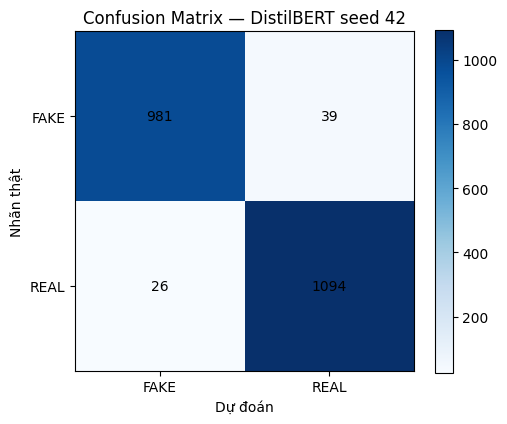

Tổng Test = 2140 | đúng = 2075 | sai = 65


In [18]:
import matplotlib.pyplot as plt

cm = np.asarray(fresh['test']['confusion_matrix_fake_real'], dtype=int)
fig, ax = plt.subplots(figsize=(5.2, 4.3))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0,1], ['FAKE','REAL'])
ax.set_yticks([0,1], ['FAKE','REAL'])
ax.set(xlabel='Dự đoán', ylabel='Nhãn thật',
       title=f'Confusion Matrix — DistilBERT seed {SEED}')
for r in range(2):
    for c in range(2):
        ax.text(c,r,str(cm[r,c]),ha='center',va='center')
fig.colorbar(im,ax=ax)
plt.tight_layout()
fig.savefig(OUT/'confusion_matrix_test_seed42.png', dpi=160)
plt.show()
print('Tổng Test =',cm.sum(), '| đúng =',np.trace(cm),
      '| sai =',cm.sum()-np.trace(cm))


In [19]:
errors = predictions['test'].loc[
    predictions['test']['label'] != predictions['test']['predicted_label']
].copy()
errors['token_count'] = [len(v) for v in tokenizer(
    errors['tweet'].fillna('').astype(str).tolist(),
    truncation=False, add_special_tokens=True)['input_ids']]
errors['has_negation'] = errors['tweet'].fillna('').astype(str).str.contains(
    r"\b(?:no|not|never|without|cannot|can't|don['’]t|doesn['’]t)\b",
    regex=True, case=False, na=False)
errors['over_128_tokens'] = errors['token_count'] > MAX_LENGTH
cols = [c for c in ['id','tweet','label','predicted_label','score_fake',
                    'score_real','token_count','has_negation','over_128_tokens']
        if c in errors.columns]
print('Số câu Test dự đoán sai:',len(errors))
print('Số câu sai có từ phủ định:',int(errors['has_negation'].sum()))
print('Số câu sai vượt 128 tokens:',int(errors['over_128_tokens'].sum()))
display(errors[cols].head(10))
errors[cols].to_csv(OUT/'test_errors_with_features.csv',index=False)
print('Lưu ý: không thể quy các lỗi này cho negation/truncation nếu chưa làm đối chứng.')


Số câu Test dự đoán sai: 65
Số câu sai có từ phủ định: 15
Số câu sai vượt 128 tokens: 0


,id,tweet,label,predicted_label,score_fake,score_real,token_count,has_negation,over_128_tokens
27,28,Govt has added #Corona disease in all existing...,fake,real,0.293483,0.706517,44,False,False
45,46,🤝 As business continue to adapt their services...,fake,real,0.001437,0.998563,87,False,False
149,150,Several sites tracking COVID-19 hit a grim mil...,real,fake,0.941590,0.058410,57,False,False
151,152,#IndiaFightsCorona: #COVID19 does not even spa...,real,fake,0.642708,0.357292,81,True,False
181,182,In response to the pandemic Pennsylvania Gover...,real,fake,0.994136,0.005864,65,False,False
184,185,*DNA Vaccine: injecting genetic material into ...,real,fake,0.744823,0.255177,35,False,False
267,268,Keep your newborn more than 6 feet away from y...,fake,real,0.304774,0.695226,45,False,False
277,278,This year Election Night could be chaotic. In ...,fake,real,0.084200,0.915800,61,False,False
290,291,@hiraj13 @madhukishwar Luckily sir for you peo...,fake,real,0.194166,0.805834,70,True,False
302,303,"Donald Trump has claimed he ""up-played"" the se...",real,fake,0.997357,0.002643,51,False,False


Lưu ý: không thể quy các lỗi này cho negation/truncation nếu chưa làm đối chứng.


## Ô 11 — Đối chiếu ba seed đã lưu trên GitHub
Đây là báo cáo cũ được đọc từ file, không phải kết quả notebook vừa train ba seed.
Mean ± std dùng độ lệch chuẩn mẫu (ddof=1). Cấu hình và SHA256 phải cùng nhau.
Seed123 được chọn cho demo theo F1 Validation, không theo Test.


In [20]:
rows, protocols = [], []
for seed in cfg['seeds']:
    base = REPORTS/f'seed{seed}'
    val = json.loads((base/'metrics.json').read_text())
    test = json.loads((base/'test_metrics.json').read_text())
    protocol = json.loads((base/'run_config.json').read_text())
    protocols.append({k:v for k,v in protocol.items() if k!='seed'})
    rows.append({'seed':seed,'Val F1 weighted (%)':100*val['val']['f1_weighted'],
                 'Test Accuracy (%)':100*test['accuracy'],
                 'Test F1 weighted (%)':100*test['f1_weighted'],
                 'Test F1 macro (%)':100*test['f1_macro'],
                 'Train seconds':val['train_seconds_this_session'],
                 'Peak GPU GiB':val['peak_cuda_allocated_gib']})
assert all(p==protocols[0] for p in protocols), 'Khác protocol giữa ba seed'
summary = pd.DataFrame(rows).set_index('seed')
display(summary.round(4))
display(pd.DataFrame({'mean':summary.mean(),'sample_std':summary.std(ddof=1)}).round(4))
summary.to_csv(OUT/'github_3seeds_summary.csv')
comparison = pd.DataFrame([
    {'metric':k,'GitHub đã lưu':reference_test[k], 'Demo vừa chạy':fresh['test'][k],
     'chênh lệch':fresh['test'][k]-reference_test[k]}
    for k in ['accuracy','f1_weighted','f1_macro','f1_fake']])
display(comparison)
if not np.allclose(comparison['chênh lệch'],0,atol=1e-10):
    print('Có chênh lệch: kiểm tra đúng model/seed, tokenizer, thư viện, max_length và dữ liệu; không sửa số để khớp.')


,Val F1 weighted (%),Test Accuracy (%),Test F1 weighted (%),Test F1 macro (%),Train seconds,Peak GPU GiB
seed,,,,,,
42,97.1954,96.9626,96.9616,96.9541,246.7699,1.3479
123,97.5224,97.2897,97.2891,97.2825,251.3744,1.3518
2024,97.1500,97.2430,97.2436,97.2382,251.2183,1.3503


,mean,sample_std
Val F1 weighted (%),97.2893,0.2032
Test Accuracy (%),97.1651,0.1769
Test F1 weighted (%),97.1648,0.1774
Test F1 macro (%),97.1583,0.1782
Train seconds,249.7875,2.6145
Peak GPU GiB,1.3500,0.0020


,metric,GitHub đã lưu,Demo vừa chạy,chênh lệch
0,accuracy,0.969626,0.969626,0.0
1,f1_weighted,0.969616,0.969616,0.0
2,f1_macro,0.969541,0.969541,0.0
3,f1_fake,0.967933,0.967933,0.0


### Bổ sung theo Lab07 — Fine-tuning 4 epoch × 3 seed, hiểu từng bước

**Đây là giải thích cấu hình của lượt train gốc, không phải khởi chạy train trong notebook demo.** Với train size 6.420, batch 8: `ceil(6420/8)=803` mini-batch/epoch. Tích lũy 4 mini-batch cho một optimizer step nên có `ceil(803/4)=201` bước cập nhật/epoch, tổng **804 bước cho 4 epoch** (theo giao thức hiện tại). `checkpoint-603` ≈ epoch 3, `checkpoint-804` ≈ epoch 4.

Ở mỗi epoch: **lặp Train → forward → CrossEntropyLoss → backward → AdamW cập nhật → đánh giá Validation → lưu checkpoint**. Seed 42, 123, 2024 là **ba lần huấn luyện độc lập từ cùng pretrained model**. Seed làm thay đổi yếu tố ngẫu nhiên, **không phải ba nhãn / ba câu trả lời**.

Chọn checkpoint dựa trên **Validation F1-weighted**, không xem kết quả Test để chọn. Ô tiếp theo in số bước và checkpoint từ hồ sơ thật đã lưu.

In [22]:
import math

n_train = len(frames['train'])
bs = int(cfg['train_batch_size'])
ga = int(cfg['gradient_accumulation_steps'])
epochs = int(cfg['epochs'])
mini_batches_per_epoch = math.ceil(n_train/bs)
updates_per_epoch = math.ceil(mini_batches_per_epoch/ga)
print('Train samples:',n_train)
print('Epochs:',epochs)
print('Train batch size:',bs)
print('Gradient accumulation:',ga)
print('Effective batch size (1 GPU):',bs*ga)
print('Mini-batches / epoch:',mini_batches_per_epoch)
print('Optimizer steps / epoch:',updates_per_epoch)
print('Optimizer steps tổng dự kiến:',epochs*updates_per_epoch)

best_rows=[]
for s in cfg['seeds']:
    record=json.loads((REPORTS/f'seed{s}/metrics.json').read_text())
    best_rows.append({'seed':s,
                      'Val F1-weighted':record['val']['f1_weighted'],
                      'Best checkpoint':str(record.get('best_checkpoint')),
                      'Train seconds':record.get('train_seconds_this_session')})
display(pd.DataFrame(best_rows))
print('Checkpoint được lấy từ báo cáo train trước đây, không phải vừa huấn luyện.')


Train samples: 6420
Epochs: 4
Train batch size: 8
Gradient accumulation: 4
Effective batch size (1 GPU): 32
Mini-batches / epoch: 803
Optimizer steps / epoch: 201
Optimizer steps tổng dự kiến: 804


,seed,Val F1-weighted,Best checkpoint,Train seconds
0,42,0.971954,/kaggle/working/covid19-fake-news-nlp/outputs/...,246.769880
1,123,0.975224,/kaggle/working/covid19-fake-news-nlp/outputs/...,251.374435
2,2024,0.971500,/kaggle/working/covid19-fake-news-nlp/outputs/...,251.218301


Checkpoint được lấy từ báo cáo train trước đây, không phải vừa huấn luyện.


## Ô 12 — Minh chứng train gốc và lưu kết quả demo
Nếu Dataset có log_history.json thì vẽ loss và F1 Validation theo epoch.
Đây là log của lượt train gốc, không phải log train mới. Tải ZIP nhỏ sau khi chạy xong.


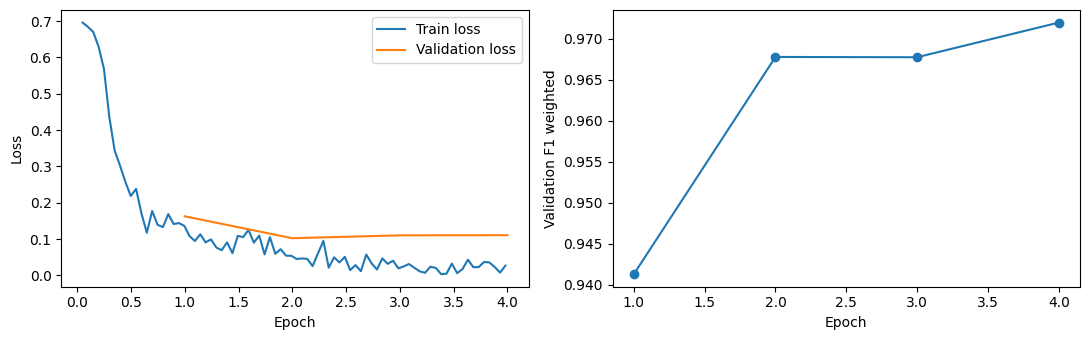

Môi trường lượt train gốc: {'python': '3.13.15', 'os': 'Linux-6.18.48+-x86_64-with-glibc2.39', 'sklearn': '1.6.1', 'pandas': '2.3.3', 'torch': '2.11.0+cu128', 'transformers': '4.57.1', 'device': 'cuda:0', 'gpu_name': 'Tesla T4', 'n_gpu': 1}
Checkpoint chọn theo Validation: /kaggle/working/covid19-fake-news-nlp/outputs/distilbert/seed_42/checkpoints/checkpoint-804
Thời gian train gốc: 246.76987966699994 giây


/kaggle/working/demo_distilbert_seed42.zip

Save Version trên Kaggle sau khi kiểm tra các output.


In [23]:
import matplotlib.pyplot as plt
log_path = RUN_DIR/'log_history.json'
if log_path.exists():
    log = pd.DataFrame(json.loads(log_path.read_text()))
    fig, axes = plt.subplots(1,2,figsize=(11,3.5))
    for column,label in [('loss','Train loss'),('eval_loss','Validation loss')]:
        if column in log:
            subset = log.dropna(subset=[column])
            axes[0].plot(subset['epoch'],subset[column],label=label)
    axes[0].set(xlabel='Epoch',ylabel='Loss'); axes[0].legend()
    if 'eval_f1_weighted' in log:
        subset=log.dropna(subset=['eval_f1_weighted'])
        axes[1].plot(subset.epoch,subset.eval_f1_weighted,marker='o')
    axes[1].set(xlabel='Epoch',ylabel='Validation F1 weighted')
    fig.tight_layout(); fig.savefig(OUT/'original_training_curves.png',dpi=160)
    plt.show()
else:
    print('Dataset không có log_history.json; không dựng lại đường cong từ metric cuối.')
original_metrics = REPORTS/f'seed{SEED}/metrics.json'
original = json.loads(original_metrics.read_text())
print('Môi trường lượt train gốc:',original['environment'])
print('Checkpoint chọn theo Validation:',original['best_checkpoint'])
print('Thời gian train gốc:',original['train_seconds_this_session'],'giây')
archive = shutil.make_archive(str(OUT),'zip',root_dir=OUT)
from IPython.display import FileLink
display(FileLink(archive))
print('Save Version trên Kaggle sau khi kiểm tra các output.')


### Đọc log Loss/F1 một cách khoa học (lượt train gốc seed 42)

`Train Loss` là lỗi trên batch huấn luyện ở các bước log; `Validation Loss` là lỗi trên tập Validation lúc đánh giá. Nếu Train Loss giảm nhưng Validation Loss tăng liên tiếp, có **dấu hiệu overfitting**. Nếu cả hai giảm, chưa thấy dấu hiệu đó, nhưng **không thể kết luận không bao giờ overfit**. Biểu đồ này **chỉ dùng log seed 42 nếu tồn tại**; không tự vẽ đường của seed 123/2024 từ metric cuối.

In [24]:
if log_path.exists():
    _raw_log = json.loads(log_path.read_text())
    logs = pd.DataFrame(_raw_log)
    train_cols = [c for c in ('epoch','step','loss') if c in logs.columns]
    val_cols = [c for c in ('epoch','step','eval_loss','eval_f1_weighted')
                if c in logs.columns]
    print('Log train có sẵn (các bước ghi loss):')
    if 'loss' in logs:
        display(logs.loc[logs['loss'].notna(),train_cols].tail(12))
    print('Các lần đánh giá validation có sẵn:')
    if 'eval_loss' in logs:
        val_logs = logs.loc[logs['eval_loss'].notna(), val_cols].copy()
        display(val_logs)
        if 'eval_f1_weighted' in val_logs and val_logs['eval_f1_weighted'].notna().any():
            best_row=val_logs.loc[val_logs['eval_f1_weighted'].idxmax()]
            print('F1 Validation cao nhất của log này ở epoch:',best_row.get('epoch'))
        if len(val_logs)>=2 and val_logs['eval_loss'].iloc[-1]>val_logs['eval_loss'].iloc[-2]:
            print('Validation Loss cuối tăng: cần so sánh cùng Train Loss để đánh giá overfitting.')
        else:
            print('Chưa có bằng chứng đủ để kết luận overfitting từ điểm cuối.')
else:
    print('Thiếu log_history.json. Không suy diễn đường Loss từ kết quả Accuracy/F1 cuối.')


Log train có sẵn (các bước ghi loss):


,epoch,step,loss
71,3.433375,690,0.0048
72,3.483188,700,0.0323
73,3.533001,710,0.0060
74,3.582814,720,0.0177
75,3.632628,730,0.0431
76,3.682441,740,0.0226
77,3.732254,750,0.0227
78,3.782067,760,0.0368
79,3.831880,770,0.0357
80,3.881694,780,0.0230


Các lần đánh giá validation có sẵn:


,epoch,step,eval_loss,eval_f1_weighted
20,1.0,201,0.162678,0.941312
41,2.0,402,0.102351,0.967767
62,3.0,603,0.110218,0.967733
83,4.0,804,0.110632,0.971954


F1 Validation cao nhất của log này ở epoch: 4.0
Validation Loss cuối tăng: cần so sánh cùng Train Loss để đánh giá overfitting.


**Khi cô hỏi “Tại sao chọn 4 epoch?”** — “Đây là cấu hình thực nghiệm ban đầu, được kiểm tra qua Validation mỗi epoch. Huấn luyện đủ tối đa 4 epoch nhưng checkpoint tốt nhất không nhất thiết là epoch 4. Ở thí nghiệm trước seed 42 chọn checkpoint-804, seed 123 và 2024 chọn checkpoint-603. Nhóm chưa làm thí nghiệm đủ rộng để tuyên bố 4 epoch là tối ưu tuyệt đối.”

## Ô 13 — Tùy chọn: chạy thử train ít mẫu để giải thích vòng học
Đổi RUN_SMOKE=True khi muốn minh họa code train → loss → chọn checkpoint → lưu model.
--smoke dùng 16 mẫu/lớp Train, 8 mẫu/lớp Validation, 1 epoch. Không dùng metric smoke làm kết quả đề tài.
Mỗi lần tạo thư mục mới để giữ kết quả trước. Chạy ô này sau phần demo chính.


In [27]:
RUN_SMOKE = True
if RUN_SMOKE:
    from datetime import datetime
    smoke_dir = Path('/kaggle/working')/('smoke_'+datetime.now().strftime('%Y%m%d_%H%M%S'))
    subprocess.run([sys.executable,'-m','src.finetune','--seed',str(SEED),'--smoke',
                    '--out-dir',str(smoke_dir)],check=True)
    print('Model thử:',smoke_dir/'model')
else:
    print('Đang tắt train thử. Đổi RUN_SMOKE=True để chạy.')


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
100%|██████████| 1/1 [00:00<00:00,  1.14it/s]
                                             
100%|██████████| 1/1 [00:01<00:00,  1.81s/it]


{'eval_loss': 0.6946901082992554, 'eval_accuracy': 0.5, 'eval_f1_weighted': 0.4181818181818182, 'eval_f1_macro': 0.4181818181818182, 'eval_f1_fake': 0.6363636363636364, 'eval_runtime': 0.0453, 'eval_samples_per_second': 353.1, 'eval_steps_per_second': 22.069, 'epoch': 1.0}
{'train_runtime': 1.8069, 'train_samples_per_second': 17.71, 'train_steps_per_second': 0.553, 'train_loss': 0.6926984786987305, 'epoch': 1.0}
{
  "architecture": "distilbert",
  "seed": 42,
  "smoke": true,
  "val": {
    "accuracy": 0.5,
    "f1_weighted": 0.4181818181818182,
    "f1_macro": 0.4181818181818182,
    "f1_fake": 0.6363636363636364,
    "confusion_matrix_fake_real": [
      [
        7,
        1
      ],
      [
        7,
        1
      ]
    ],
    "classification_report": {
      "fake": {
        "precision": 0.5,
        "recall": 0.875,
        "f1-score": 0.6363636363636364,
        "support": 8.0
      },
      "real": {
        "precision": 0.5,
        "recall": 0.125,
        "f1-score": 0.

100%|██████████| 1/1 [00:00<00:00, 80.50it/s]


Model thử: /kaggle/working/smoke_20261109_123742/model


## Ô 14 — Tùy chọn: train đầy đủ lại một seed
Đổi RUN_FULL_TRAIN=True để chạy đúng src.finetune, 4 epoch, model gốc pretrained.
Giữ config giống nhau giữa ba seed. Lượt mới có thể khác số cuối do phần cứng và thư viện.
Không chạy ba seed trong thời gian trình bày nếu chưa chuẩn bị trước.


In [28]:
RUN_FULL_TRAIN = True
if RUN_FULL_TRAIN:
    from datetime import datetime
    new_run = Path('/kaggle/working')/('retrain_'+datetime.now().strftime('%Y%m%d_%H%M%S'))/f'seed_{SEED}'
    subprocess.run([sys.executable,'-m','src.finetune','--seed',str(SEED),
                    '--out-dir',str(new_run)],check=True)
    print(json.dumps(json.loads((new_run/'metrics.json').read_text()),indent=2,ensure_ascii=False))
else:
    print('Đang tắt train đầy đủ. Đổi RUN_FULL_TRAIN=True để chạy.')


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  2%|▏         | 3/134 [00:00<00:05, 24.49it/s]

{'loss': 0.6961, 'grad_norm': 1.5048540830612183, 'learning_rate': 2.222222222222222e-06, 'epoch': 0.05}
{'loss': 0.6844, 'grad_norm': 1.059084177017212, 'learning_rate': 4.691358024691358e-06, 'epoch': 0.1}
{'loss': 0.6702, 'grad_norm': 0.8460246324539185, 'learning_rate': 7.160493827160494e-06, 'epoch': 0.15}
{'loss': 0.6297, 'grad_norm': 1.5808743238449097, 'learning_rate': 9.62962962962963e-06, 'epoch': 0.2}
{'loss': 0.5684, 'grad_norm': 2.2942421436309814, 'learning_rate': 1.2098765432098767e-05, 'epoch': 0.25}
{'loss': 0.436, 'grad_norm': 4.839997291564941, 'learning_rate': 1.4567901234567903e-05, 'epoch': 0.3}
{'loss': 0.3436, 'grad_norm': 7.139233589172363, 'learning_rate': 1.7037037037037038e-05, 'epoch': 0.35}
{'loss': 0.3021, 'grad_norm': 5.560264587402344, 'learning_rate': 1.9506172839506175e-05, 'epoch': 0.4}
{'loss': 0.2574, 'grad_norm': 1.4995704889297485, 'learning_rate': 1.9778699861687415e-05, 'epoch': 0.45}
{'loss': 0.2186, 'grad_norm': 3.3015284538269043, 'learning_


 97%|█████████▋| 130/134 [00:06<00:00, 18.80it/s]
                                                 
 50%|█████     | 402/804 [02:01<01:42,  3.92it/s]

{'eval_loss': 0.16267800331115723, 'eval_accuracy': 0.9415887850467289, 'eval_f1_weighted': 0.9413116984086307, 'eval_f1_macro': 0.9410478063723464, 'eval_f1_fake': 0.9354005167958657, 'eval_runtime': 7.2654, 'eval_samples_per_second': 294.546, 'eval_steps_per_second': 18.444, 'epoch': 1.0}
{'loss': 0.108, 'grad_norm': 9.415884971618652, 'learning_rate': 1.6459197786998618e-05, 'epoch': 1.04}
{'loss': 0.0947, 'grad_norm': 5.002502918243408, 'learning_rate': 1.6182572614107886e-05, 'epoch': 1.09}
{'loss': 0.1131, 'grad_norm': 4.011549949645996, 'learning_rate': 1.590594744121715e-05, 'epoch': 1.14}
{'loss': 0.0909, 'grad_norm': 4.013909339904785, 'learning_rate': 1.562932226832642e-05, 'epoch': 1.19}
{'loss': 0.0991, 'grad_norm': 5.119060039520264, 'learning_rate': 1.5352697095435688e-05, 'epoch': 1.24}
{'loss': 0.0767, 'grad_norm': 12.212320327758789, 'learning_rate': 1.5076071922544952e-05, 'epoch': 1.29}
{'loss': 0.0693, 'grad_norm': 4.171503067016602, 'learning_rate': 1.479944674965


 96%|█████████▋| 129/134 [00:06<00:00, 19.41it/s]
                                                 
  2%|▏         | 3/134 [00:00<00:04, 26.61it/s]

{'eval_loss': 0.10235123336315155, 'eval_accuracy': 0.9677570093457943, 'eval_f1_weighted': 0.9677669585553142, 'eval_f1_macro': 0.9677084337934324, 'eval_f1_fake': 0.966456003889159, 'eval_runtime': 6.8478, 'eval_samples_per_second': 312.508, 'eval_steps_per_second': 19.568, 'epoch': 2.0}
{'loss': 0.0452, 'grad_norm': 0.16056589782238007, 'learning_rate': 1.0926694329183956e-05, 'epoch': 2.04}
{'loss': 0.0466, 'grad_norm': 0.10126698762178421, 'learning_rate': 1.0650069156293224e-05, 'epoch': 2.09}
{'loss': 0.0453, 'grad_norm': 6.30190896987915, 'learning_rate': 1.0373443983402491e-05, 'epoch': 2.14}
{'loss': 0.0256, 'grad_norm': 1.0715783834457397, 'learning_rate': 1.0096818810511757e-05, 'epoch': 2.19}
{'loss': 0.061, 'grad_norm': 2.3981125354766846, 'learning_rate': 9.820193637621024e-06, 'epoch': 2.24}
{'loss': 0.0949, 'grad_norm': 6.274755477905273, 'learning_rate': 9.543568464730292e-06, 'epoch': 2.29}
{'loss': 0.0213, 'grad_norm': 0.05179580673575401, 'learning_rate': 9.2669432

... (2 outputs left out)


 96%|█████████▋| 129/134 [00:06<00:00, 19.55it/s]
                                                 
100%|██████████| 804/804 [04:19<00:00,  3.10it/s]


{'eval_loss': 0.11063249409198761, 'eval_accuracy': 0.9719626168224299, 'eval_f1_weighted': 0.9719543659398062, 'eval_f1_macro': 0.9718856085846111, 'eval_f1_fake': 0.9704142011834319, 'eval_runtime': 6.8732, 'eval_samples_per_second': 311.354, 'eval_steps_per_second': 19.496, 'epoch': 4.0}
{'train_runtime': 259.5845, 'train_samples_per_second': 98.927, 'train_steps_per_second': 3.097, 'train_loss': 0.11588205386472133, 'epoch': 4.0}


100%|██████████| 134/134 [00:06<00:00, 19.81it/s]


{
  "architecture": "distilbert",
  "seed": 42,
  "smoke": false,
  "val": {
    "accuracy": 0.9719626168224299,
    "f1_weighted": 0.9719543659398062,
    "f1_macro": 0.9718856085846111,
    "f1_fake": 0.9704142011834319,
    "confusion_matrix_fake_real": [
      [
        984,
        36
      ],
      [
        24,
        1096
      ]
    ],
    "classification_report": {
      "fake": {
        "precision": 0.9761904761904762,
        "recall": 0.9647058823529412,
        "f1-score": 0.9704142011834319,
        "support": 1020.0
      },
      "real": {
        "precision": 0.9681978798586572,
        "recall": 0.9785714285714285,
        "f1-score": 0.9733570159857904,
        "support": 1120.0
      },
      "accuracy": 0.9719626168224299,
      "macro avg": {
        "precision": 0.9721941780245666,
        "recall": 0.9716386554621849,
        "f1-score": 0.9718856085846111,
        "support": 2140.0
      },
      "weighted avg": {
        "precision": 0.9720074351196177,
   

## Ô 15 — Tùy chọn: đánh giá Test và lưu model của lượt train mới
Chỉ chạy sau ô 14 hoàn tất, với cấu hình đã chốt. src.evaluate dùng CPU từng câu nên
có thể chậm hơn ô 9. ZIP này giữ model/tokenizer/log/cấu hình, bỏ optimizer checkpoint để nhẹ hơn.


In [29]:
EVALUATE_NEW_RUN = True
if EVALUATE_NEW_RUN:
    if 'new_run' not in globals() or not (new_run/'completed.flag').exists():
        raise RuntimeError('Chưa có lượt train đầy đủ hoàn tất từ ô 14.')
    if not (new_run/'test_metrics.json').exists():
        subprocess.run([sys.executable,'-m','src.evaluate','--run-dir',str(new_run),
                        '--confirm-config-frozen'],check=True)
    saved_zip = new_run.parent/f'distilbert_seed{SEED}_model_and_metrics.zip'
    with zipfile.ZipFile(saved_zip,'w',zipfile.ZIP_DEFLATED) as z:
        for path in new_run.rglob('*'):
            if path.is_file() and 'checkpoints' not in path.relative_to(new_run).parts:
                z.write(path,Path(f'seed_{SEED}')/path.relative_to(new_run))
    display(FileLink(str(saved_zip)))
else:
    print('Đang tắt đánh giá và đóng gói lượt train mới.')


{
  "accuracy": 0.969626168224299,
  "f1_weighted": 0.9696163979571536,
  "f1_macro": 0.9695412420560341,
  "f1_fake": 0.9679329057720769,
  "confusion_matrix_fake_real": [
    [
      981,
      39
    ],
    [
      26,
      1094
    ]
  ],
  "classification_report": {
    "fake": {
      "precision": 0.974180734856008,
      "recall": 0.961764705882353,
      "f1-score": 0.9679329057720769,
      "support": 1020.0
    },
    "real": {
      "precision": 0.9655781112091791,
      "recall": 0.9767857142857143,
      "f1-score": 0.9711495783399912,
      "support": 1120.0
    },
    "accuracy": 0.969626168224299,
    "macro avg": {
      "precision": 0.9698794230325936,
      "recall": 0.9692752100840336,
      "f1-score": 0.9695412420560341,
      "support": 2140.0
    },
    "weighted avg": {
      "precision": 0.9696784271529948,
      "recall": 0.969626168224299,
      "f1-score": 0.9696163979571536,
      "support": 2140.0
    }
  },
  "dataset_sha256": "a63347e8f01ead0d923b55b61

/kaggle/working/retrain_20261109_123826/distilbert_seed42_model_and_metrics.zip

## Tổng kết — checklist thuyết trình và lưu kết quả

- **Dữ liệu:** 10.700 mẫu chia sẵn Train/Validation/Test; nhãn `fake`/`real`, giữ nguyên split gốc và đối chiếu SHA256. Đọc kết quả kiểm tra overlap trước khi khẳng định đánh giá công bằng.
- **Xử lý:** tokenizer `distilbert-base-uncased` → token ID và attention mask → padding động → batch 8, giới hạn 128 token.
- **Mô hình:** DistilBERT pretrained 6 encoder, classification head 2 logits, Cross-Entropy Loss, AdamW, gradient accumulation 4, huấn luyện 4 epoch.
- **Thực nghiệm:** ba seed 42/123/2024 độc lập, checkpoint chọn theo Validation F1 weighted; seed 42 là checkpoint đang nạp trong notebook này.
- **Kết quả:** Dùng bảng `Ô 11` để đọc đúng ba seed **đã lưu trên GitHub** và `Ô 9–10` để kiểm tra lại checkpoint seed42. Không nói notebook hiện tại vừa chạy lại cả ba seed.
- **Phân tích lỗi:** phân biệt bỏ lọt tin giả (Fake→Real) và báo nhầm tin thật (Real→Fake); Loss và câu sai không đủ để xác định chắc chắn nguyên nhân.
- **Chạy Kaggle:** khi import lại, cần `Add Input` đúng dataset checkpoint và mã nguồn. Không bật các lệnh train/retrain ở cuối nếu chỉ cần demo. **Save Version** để lưu outputs mới sau khi chạy.

> *Giới hạn:* Các ô giải thích/bổ sung trong bản này không có output thực thi sẵn. Nếu cảnh báo trùng Train–Test xuất hiện, cần báo cáo trung thực và xem xét thiết kế đánh giá bổ sung; không tự động loại mẫu khỏi bộ chuẩn rồi giữ nguyên metric cũ.